# Module 13: initial designs (Sobol, Latin hypercube, factorial designs, Morris screening)

**Theory:** course Module 13. Before any model exists, only geometry can place the first runs. This notebook builds each
design, checks its defining property, measures what it does to the first surrogate, and ends with the esmini cut-in.
Harness: `failreg/` (notebook 32). CPU only, about one minute.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
HERE = Path.cwd().resolve()
HERE = HERE if (HERE / "failreg").exists() else HERE / "notebooks/course"
sys.path.insert(0, str(HERE))
from failreg import problems as P, metrics as M, designs as D, models as MD, acquisition as A, replication as R, loop as L, plots as PL
warnings.filterwarnings("ignore")
PL.style(); T0 = time.time()

## 1. Five space-filling designs at n = 16

Uniform random; Latin hypercube (one point per interval of every axis; Santner et al. 2018); maximin LHS (best of 50 by
minimum distance); scrambled Sobol' (extensible, balanced at powers of two); FSSF (Shang & Apley 2020: from a Sobol'
candidate set of 1000d + 2n points, add the candidate furthest from the design, one at a time).

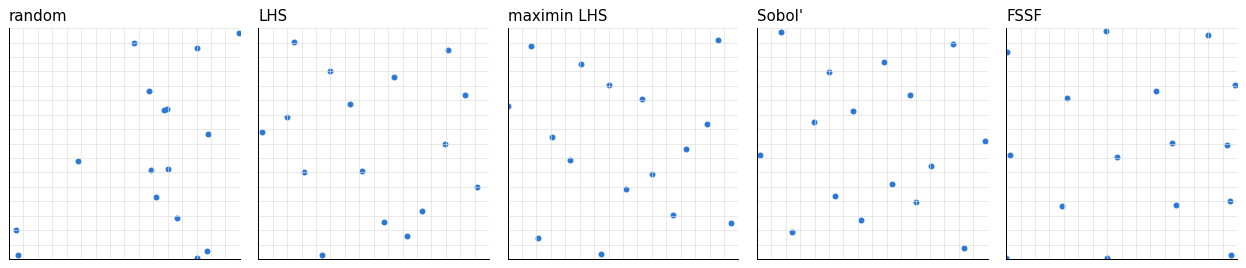

design        min distance  discrepancy  empty 1-D bins   (medians over 20 seeds, n = 16, d = 2)
random               0.047       0.0203            0.41
LHS                  0.090       0.0028            0.00
maximin LHS          0.142       0.0027            0.00
Sobol'               0.119       0.0022            0.00
FSSF                 0.250       0.0151            0.50


In [2]:
DES = {"random": D.random, "LHS": D.lhs, "maximin LHS": D.maximin_lhs, "Sobol'": D.sobol, "FSSF": D.fssf}
fig, axs = plt.subplots(1, 5, figsize=(14, 2.9))
for ax, (name, f) in zip(axs, DES.items()):
    X = f(16, 2, seed=0)
    ax.scatter(X[:, 0], X[:, 1], s=14, c=PL.BLUE)
    for g in np.linspace(0, 1, 17): ax.axvline(g, color="#ddd", lw=0.5); ax.axhline(g, color="#ddd", lw=0.5)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(name, loc="left")
plt.tight_layout(); plt.show()
print(f"{'design':12s} {'min distance':>13s} {'discrepancy':>12s} {'empty 1-D bins':>15s}   (medians over 20 seeds, n = 16, d = 2)")
for name, f in DES.items():
    r = np.array([[D.min_distance(X), D.discrepancy(X), D.projection_gaps(X)] for X in (f(16, 2, seed=s) for s in range(20))])
    print(f"{name:12s} {np.median(r[:, 0]):13.3f} {np.median(r[:, 1]):12.4f} {np.median(r[:, 2]):15.2f}")

## 2. Extensible or not

A Sobol' prefix of size 2ᵐ is itself balanced, so the same sequence is both the initial design and the baseline at any
budget. An LHS is Latin only at its own n: the first 16 points of an LHS of 32 leave intervals empty. FSSF keeps a large
minimum distance at every prefix.

In [3]:
S, Lh, F = D.sobol(64, 2, 1), D.lhs(64, 2, 1), D.fssf(64, 2, 1)
for n in (8, 16, 32, 64):
    print(f"first {n:2d} points: empty 1/n bins  Sobol' {D.projection_gaps(S[:n]):.2f}  LHS(64) {D.projection_gaps(Lh[:n]):.2f}"
          f"   | min distance  Sobol' {D.min_distance(S[:n]):.3f}  FSSF {D.min_distance(F[:n]):.3f}")

first  8 points: empty 1/n bins  Sobol' 0.00  LHS(64) 0.38   | min distance  Sobol' 0.300  FSSF 0.372
first 16 points: empty 1/n bins  Sobol' 0.00  LHS(64) 0.38   | min distance  Sobol' 0.078  FSSF 0.271
first 32 points: empty 1/n bins  Sobol' 0.00  LHS(64) 0.28   | min distance  Sobol' 0.037  FSSF 0.164
first 64 points: empty 1/n bins  Sobol' 0.00  LHS(64) 0.00   | min distance  Sobol' 0.037  FSSF 0.103


## 3. A two-level fractional factorial: 2⁸⁻⁴, resolution IV

Generators E = BCD, F = ACD, G = ABC, H = ABD. The shortest word of the defining relation sets the resolution
(Wu & Hamada 2021): resolution IV keeps main effects clear of two-factor interactions. Check FᵀF = nI.
A two-level design only sees corners: a curved failure boundary passes between them (right panel, the car-following
problem with a 2² design).

runs: 16 | F^T F = 16 I: True | resolution: 4
defining relation I = ABCG = ABDH = ABEF = ACDF = ACEH = ADEG = AFGH = BCDE = BCFH = BDFG = BEGH = CDGH = CEFG = DEFH = ABCDEFGH


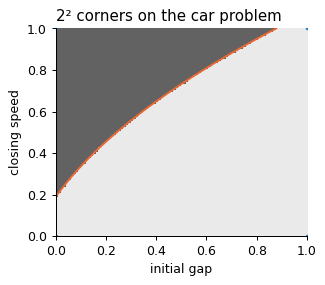

corner outcomes (fails?): [0 0 1 0] - no corner lies near the boundary


In [4]:
Ff, names = D.fractional_factorial(8, ["BCD", "ACD", "ABC", "ABD"])
words, res = D.defining_relation(8, ["BCD", "ACD", "ABC", "ABD"])
print("runs:", len(Ff), "| F^T F = 16 I:", np.allclose(Ff.T @ Ff, 16 * np.eye(8)), "| resolution:", res)
print("defining relation I =", " = ".join(words))
pc = P.get("car"); C2 = (D.fractional_factorial(2, [])[0] + 1) / 2
fig, ax = plt.subplots(figsize=(3.6, 3)); PL.region_map(ax, pc, X=C2, title="2² corners on the car problem")
c = P.car_zero_contour(); ax.plot(c[:, 0], c[:, 1], color=PL.ORANGE); plt.show()
print("corner outcomes (fails?):", pc.fails(C2).astype(int), "- no corner lies near the boundary")

## 4. Morris screening

r = 10 trajectories on a p = 4 level grid, Δ = p / (2(p − 1)) = 2/3, so r(d + 1) = 90 runs at d = 8 (Saltelli et al. 2008).
μ* = mean |EE| ranks the inputs, σ flags non-linearity or interaction. Test: the 3-input car-following gap (initial gap,
closing speed, reaction time) plus 5 inert inputs. Then the same with run-to-run noise (sd 5 m), against a pure-noise null
(μ* of noise alone, 200 draws): screening needs signal (Module 13, §3).

In [5]:
d = 8; Xm, which, delta = D.morris(d, r=10, p=4, seed=0)
f8 = lambda X: P.car_following(X[:, :3])
mu_star, sigma = D.morris_effects(Xm, f8(Xm), which, d)
rng = np.random.default_rng(0); noise = 5.0
mu_noisy, _ = D.morris_effects(Xm, f8(Xm) + noise * rng.standard_normal(len(Xm)), which, d)
null = np.array([D.morris_effects(Xm, noise * rng.standard_normal(len(Xm)), which, d)[0] for _ in range(200)])
q95 = np.quantile(null, 0.95, axis=0)
print(f"{len(Xm)} runs, delta = {delta:.3f}")
print(f"{'input':10s} {'mu*':>8s} {'sigma':>8s} {'mu* noisy':>10s} {'null 95%':>9s}  above null?")
for j in range(d):
    nm = ["gap", "closing", "reaction"][j] if j < 3 else f"inert {j - 2}"
    print(f"{nm:10s} {mu_star[j]:8.2f} {sigma[j]:8.2f} {mu_noisy[j]:10.2f} {q95[j]:9.2f}  {mu_noisy[j] > q95[j]}")

90 runs, delta = 0.667
input           mu*    sigma  mu* noisy  null 95%  above null?
gap           55.00     0.00      52.96     11.77  True
closing       78.44     6.99      72.39     11.54  True
reaction      22.00    10.33      24.72     11.70  True
inert 1        0.00     0.00       9.68     11.53  False
inert 2        0.00     0.00       8.03     11.85  False
inert 3        0.00     0.00       9.24     11.95  False
inert 4        0.00     0.00       6.98     11.58  False
inert 5        0.00     0.00       6.98     11.66  False


## 5. The initial design decides the early picture

A GP fitted to n₀ points from each design, misclassified share on Branin (10 seeds). Then Batsch et al. 2019's check: two
independent designs of the same size give two boundary estimates; how far apart are they (maximum distance)?

In [6]:
pb = P.get("branin"); G, truth, shape, _ = pb.test
print(f"{'design':12s}" + "".join(f"{'n0=' + str(n):>10s}" for n in (8, 16, 32)) + "   misclassified %, median of 10 seeds")
for name in ("random", "LHS", "maximin LHS", "Sobol'", "FSSF"):
    row = []
    for n in (8, 16, 32):
        row.append(np.median([100 * L.static(pb, DES[name], n, s, lambda: MD.GPR())[0][-1]["misclassified"] for s in range(10)]))
    print(f"{name:12s}" + "".join(f"{v:10.2f}" for v in row))
for name in ("random", "LHS"):
    dist = []
    for s in range(5):
        b = []
        for k in (0, 1):
            X = DES[name](30, 2, seed=100 * s + k); m = MD.GPR().fit(X, pb.f(X))
            b.append(M.boundary_points(L.region(pb, m, G), shape))
        dist.append(M.boundary_distance(*b)["max"])
    print(f"two independent {name} designs of 30: max distance between their boundaries, median {np.median(dist):.3f} (unit box)")

design            n0=8     n0=16     n0=32   misclassified %, median of 10 seeds


random           17.64      8.31      1.42


LHS              16.29     10.89      0.84


maximin LHS      15.93      7.66      0.89


Sobol'           17.09     13.72      0.81


FSSF             15.83     10.75      0.89


two independent random designs of 30: max distance between their boundaries, median 0.081 (unit box)


two independent LHS designs of 30: max distance between their boundaries, median 0.030 (unit box)


## 6. How many initial points, at a fixed budget?

GP-AL (straddle) with a total of 48 runs on Branin, starting from 4, 16 or 32 Sobol' points (5 seeds). No verified rule
exists; Lyu et al. 2021 use n₀ = 10d from an LHS. And on a large smooth region a space-filling design run to the budget
can tie active learning: the `car` problem.

In [7]:
for n0 in (4, 16, 32):
    v = [100 * L.active(pb, lambda: MD.GPR(), L.by_score(A.straddle), 48, s, n0=n0, batch=4)[0][-1]["misclassified"] for s in range(5)]
    print(f"n0 = {n0:2d}: misclassified % at 48 runs, median {np.median(v):.3f}  (seeds {np.round(v, 3)})")
for arm, h in (("GP-AL", lambda s: L.active(pc, lambda: MD.GPR(), L.by_score(A.straddle), 32, s, n0=16, batch=4)[0]),
               ("Sobol'", lambda s: L.static(pc, D.sobol, 32, s, lambda: MD.GPR())[0])):
    print(f"car problem, {arm:6s} at 32 runs: misclassified % median {np.median([100 * h(s)[-1]['misclassified'] for s in range(5)]):.3f}")

n0 =  4: misclassified % at 48 runs, median 0.049  (seeds [0.049 0.01  0.049 0.01  0.059])


n0 = 16: misclassified % at 48 runs, median 0.029  (seeds [0.02  0.02  0.029 0.059 0.069])


n0 = 32: misclassified % at 48 runs, median 0.078  (seeds [0.088 0.078 0.098 0.02  0.078])


car problem, GP-AL  at 32 runs: misclassified % median 0.000


car problem, Sobol' at 32 runs: misclassified % median 0.000


## 7. esmini cut-in

Four initial designs of 16 runs on the esmini cut-in slice (ego 30 m/s; gap at cut-in × relative speed), a GP on each,
scored against the reference grid. Then the Sobol' design simply continued to 64 runs: the non-adaptive baseline an
adaptive method has to beat (notebook 15).

In [8]:
from failreg import esmini_case as E
ec = E.cutin(); t = time.time(); res = {}
for name in ("random", "LHS", "Sobol'", "FSSF"):
    res[name] = [100 * L.static(ec, DES[name], 16, s, lambda: MD.GPR())[0][-1]["misclassified"] for s in range(3)]
base = [L.static(ec, D.sobol, 64, s, lambda: MD.GPR(), [16, 32, 64])[0] for s in range(3)]
print(f"{ec.calls} esmini runs in {time.time() - t:.0f} s")
for k, v in res.items(): print(f"{k:7s} 16 runs: misclassified % {np.round(v, 2)}")
print("Sobol' continued, median misclassified % at 16 / 32 / 64:", [round(100 * np.median(L.table(base, 'misclassified', n)), 2) for n in (16, 32, 64)])

384 esmini runs in 17 s
random  16 runs: misclassified % [1.82 9.83 2.4 ]
LHS     16 runs: misclassified % [2.03 5.94 3.17]
Sobol'  16 runs: misclassified % [1.76 2.7  2.13]
FSSF    16 runs: misclassified % [1.93 1.45 1.69]
Sobol' continued, median misclassified % at 16 / 32 / 64: [2.13, 2.26, 1.49]


## References

- T. J. Santner, B. J. Williams, W. I. Notz, *The Design and Analysis of Computer Experiments*, 2nd ed., Springer, 2018 (LHS; quasi-random designs are extensible).
- B. Shang, D. W. Apley, "Fully-sequential space-filling design algorithms for computer experiments," J. Quality Technology, 2020, doi:10.1080/00224065.2019.1705207 (FSSF).
- C. F. J. Wu, M. S. Hamada, *Experiments: Planning, Analysis, and Optimization*, 3rd ed., Wiley, 2021 (fractions, resolution).
- A. Saltelli et al., *Global Sensitivity Analysis: The Primer*, Wiley, 2008 (Morris trajectories, μ*, p = 4, r = 10).
- F. Batsch, A. Daneshkhah, M. Cheah, S. Kanarachos, A. Baxendale, "Performance Boundary Identification for the Evaluation of Automated Vehicles using Gaussian Process Classification," IEEE ITSC 2019, arXiv:1907.05364 (MC vs LHS designs, distance between boundary estimates).
- F. Batsch, A. Daneshkhah, V. Palade, M. Cheah, "Scenario Optimisation and Sensitivity Analysis for Safe Automated Driving Using Gaussian Processes," Applied Sciences 11(2), 775, 2021 (LHS initial set).
- X. Lyu, M. Binois, M. Ludkovski, "Evaluating Gaussian Process Metamodels and Sequential Designs for Noisy Level Set Estimation," Statistics and Computing 31, 2021 (n₀ = 10d from an LHS).

In [9]:
print(f"notebook ran in {time.time() - T0:.0f} s")

notebook ran in 91 s
